### Before fiting
* Load a 2D data file 
* Create a new _red.dat file with a reduced number of points

run using global (Python 3.12.10) on PC fixe 

import all the packages

In [6]:
import numpy as np

# import sasmodels
import sasmodels
import sasmodels.core
import sasmodels.data
import sasmodels.bumps_model

import sasdata

from sasdata.dataloader.loader import Loader
from sasmodels.data import load_data
#from sas import sascalc.dataloader

from sasmodels.data import plot_theory

import bumps
import bumps.fitters
import bumps.names
import bumps.fitproblem

import os



In [7]:

"""
import matplotlib.pyplot and set custom default settings for plots
"""
%matplotlib inline
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')


import matplotlib.pyplot as plt
#from IPython.display import set_matplotlib_formats
#set_matplotlib_formats('svg')

plt.rc('font', size=14) # default fontsize
plt.rc('axes', titlesize=16)
plt.rc('axes', labelsize=16)
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('legend', fontsize=14)
plt.rc('legend', title_fontsize=14)
plt.rc('figure', titlesize=18)
plt.rc("figure", figsize=(5,5))
plt.rc("lines", linewidth=3)

#import tol_colors as tc # colorblind safe color palettes

# use colorblind safe colors:
#plt.rc('axes', prop_cycle=plt.cycler('color', list(tc.tol_cset('muted'))))
#try:
#    plt.cm.register_cmap('tc_iridescent', tc.tol_cmap('iridescent'))
#except:
#    pass

#plt.rc('image', cmap='tc_iridescent')

#plt.rc('image', cmap='rainbow')
plt.rc('image', cmap='jet')



### file selection

nematic phase under E field SWING data
* .dat file obtained from SAXSProcessor by Nicolas

In [8]:
#filename="./images/Isotropic/sasview_exports/160V_236.dat"
filename="./2D-data-examples/114V_234.dat"


### data loader method

In [9]:

data2d=sasmodels.data.load_data(filename)

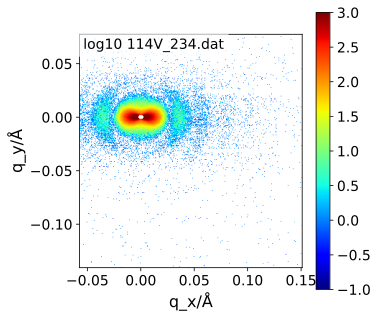

In [10]:
sasmodels.data.plot_data(data2d,view='log',limits=[0.1,1000])

#limits in intensity.

* store in I_all, qx_all and qy_all

In [11]:
I_all=data2d.data
#all intensity value sin data2d...
qx_all=data2d.qx_data
qy_all=data2d.qy_data

* rebuilt a data set

In [12]:
data_all = sasmodels.data.Data2D(x=qx_all, y=qy_all, z=I_all,dx=None,dy=None,dz=None)

#dx, dy, dz None, no errors

### reduce the number of data points before fiting

TO DO: add a circle in the middle to exclude the beamstop region

* create a numpy array
* ROI with qmax_x and qmax_y
* add a I_min value to avoir data points equal to zero  ... 
* errors proportionnal to intensity values (usually 10%)
* USE slicing=1 for a nice output with all data points in the ROI

100856
3362


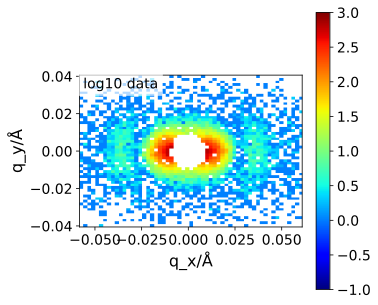

In [13]:
number_all=I_all.shape[0]

data_np=[]

# minvalue for data2d
I_min=0.0001

#error coefficient I*coefficient 
error_coeff=0.05
#error_min=0.000000

#ROI
qmax_x=0.06
qmax_y=0.04

#exclude a circle around the beamstop

q_center=0.01
#mask center radius...

#rectangular mask:

qmax_x_R=0.015
qmax_y_R=0.005

for i in range(number_all):
    if I_all[i]> I_min and (-qmax_x)<qx_all[i]<qmax_x and (-qmax_y)<qy_all[i]<qmax_y and (qx_all[i]**2+qy_all[i]**2)>q_center**2 :
#    print(I_all[i])
        data_np.append([qx_all[i],qy_all[i],abs(I_all[i]),error_coeff*abs(I_all[i])])

data_np=np.array(data_np) 

size=data_np.shape[0]


print(size)

#slicing equal to one for keeping all data points in the ROI
#slicing=20
slicing=30

data_reduced_ROI = sasmodels.data.Data2D(x=data_np[0:size:slicing,0], 
                                     y=data_np[0:size:slicing,1], 
                                     z=data_np[0:size:slicing,2],
                                     dx=None,dy=None,
                                     dz=data_np[0:size:slicing,3])

sasmodels.data.plot_data(data_reduced_ROI,view="log",limits=[0.1,1000])
size_reduced=data_np[0:size:slicing,0].shape[0]
print(size_reduced)

### Save the reduced data in a new file with _red at the end of the name

In [14]:
newfilename=filename[:-4]+"_red.dat" # data 

headertxt='Data columns Qx - Qy - I(Qx,Qy)'+'\n'+'ASCII data'

with open(newfilename, "w") as f:
     f.write("Data columns Qx - Qy - I(Qx,Qy)"+"\n")
     f.write("ASCII data"+"\n")

np.savetxt(newfilename,np.column_stack([data_reduced_ROI.qx_data,data_reduced_ROI.qy_data,data_reduced_ROI.data,data_reduced_ROI.err_data]),header=headertxt)